# Google Play Store Analysis

## Objective

The objective of this project is to analyze Google Play Store applications
to understand app categories, ratings, installs, pricing, size, and user
sentiment. The analysis aims to identify useful insights for developers
planning to launch a new application.

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- VADER Sentiment Analysis
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

from nltk.sentiment.vader import SentimentIntensityAnalyzer

import nltk

In [3]:
apps = pd.read_csv(r"C:\Users\hemas\OneDrive\Desktop\Python\googleplaystore.csv")
review = pd.read_csv(r"C:\Users\hemas\OneDrive\Desktop\Python\googleplaystore_user_reviews.csv")

In [4]:
print("Apps dataset Shape :",apps.shape)
print("Review dataset shape :",review.shape)

Apps dataset Shape : (10841, 13)
Review dataset shape : (64295, 5)


In [5]:
apps.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [6]:
review.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


## 1.Initial data inspection

In [7]:
apps.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [8]:
review.info()

<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  str    
 1   Translated_Review       37427 non-null  str    
 2   Sentiment               37432 non-null  str    
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), str(3)
memory usage: 2.5 MB


In [9]:
print(apps.columns)

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='str')


In [10]:
print(review.columns)

Index(['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity',
       'Sentiment_Subjectivity'],
      dtype='str')


In [11]:
apps.describe(include='all')

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10841,10841,9367.000000,10841,10841,10841,10840,10841,10840,10841,10841,10833,10838
unique,9660,34,NaN,6002,462,22,3,93,6,120,1378,2832,33
top,ROBLOX,FAMILY,NaN,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,"August 3, 2018",Varies with device,4.1 and up
freq,9,1972,NaN,596,1695,1579,10039,10040,8714,842,326,1459,2451
mean,NaN,NaN,4.193338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,0.537431,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,4.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
review.describe(include='all')

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
count,64295,37427,37432,37432.000000,37432.000000
unique,1074,27994,3,NaN,NaN
top,Angry Birds Classic,Good,Positive,NaN,NaN
freq,320,247,23998,NaN,NaN
mean,NaN,NaN,NaN,0.182146,0.492704
std,NaN,NaN,NaN,0.351301,0.259949
min,NaN,NaN,NaN,-1.000000,0.000000
25%,NaN,NaN,NaN,0.000000,0.357143
50%,NaN,NaN,NaN,0.150000,0.514286
75%,NaN,NaN,NaN,0.400000,0.650000


## 2.Data Cleaning

In [13]:
apps.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [14]:
review.isnull().sum()

App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

In [15]:
apps.duplicated().sum()

np.int64(483)

In [16]:
review.duplicated().sum()

np.int64(33616)

In [17]:
apps = apps.drop_duplicates()
review = review.drop_duplicates()

In [18]:
print("Apps duplicates:",apps.duplicated().sum())
print("Review duplicates:",review.duplicated().sum())

Apps duplicates: 0
Review duplicates: 0


In [19]:
apps['Installs'].unique()[:20]

<StringArray>
[       '10,000+',       '500,000+',     '5,000,000+',    '50,000,000+',
       '100,000+',        '50,000+',     '1,000,000+',    '10,000,000+',
         '5,000+',   '100,000,000+', '1,000,000,000+',         '1,000+',
   '500,000,000+',            '50+',           '100+',           '500+',
            '10+',             '1+',             '5+',             '0+']
Length: 20, dtype: str

In [20]:
apps['Installs'] = (
    apps['Installs']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)
apps['Installs'] = pd.to_numeric(apps['Installs'],errors='coerce')

In [21]:
apps[apps['Installs'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",NaN,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [22]:
apps=apps.dropna(subset=['Installs'])

In [23]:
apps['Installs'].isna().sum()

np.int64(0)

In [24]:
apps['Installs'].dtype

dtype('float64')

In [25]:
apps['Price'].unique()[:20]

<StringArray>
[     '0',  '$4.99',  '$3.99',  '$6.99',  '$1.49',  '$2.99',  '$7.99',
  '$5.99',  '$3.49',  '$1.99',  '$9.99',  '$7.49',  '$0.99',  '$9.00',
  '$5.49', '$10.00', '$24.99', '$11.99', '$79.99', '$16.99']
Length: 20, dtype: str

In [26]:
apps['Price'] = (
    apps['Price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .astype(float)
)

In [27]:
apps["Price"].dtype

dtype('float64')

In [28]:
apps['Reviews'].dtype

<StringDtype(storage='python', na_value=nan)>

In [29]:
apps['Reviews'] = pd.to_numeric(apps['Reviews'], errors='coerce')

In [30]:
apps['Rating'].describe()

count    8892.000000
mean        4.187877
std         0.522377
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64

In [31]:
apps['Rating'] = apps['Rating'].fillna(apps['Rating'].median())

In [32]:
apps['Rating'].isnull().sum()

np.int64(0)

In [33]:
def convert_size(size):
    size = str(size)

    if size == 'nan':
        return np.nan
    if 'M' in size:
        return float(size.replace('M', ''))
    if 'k' in size:
        return float(size.replace('k', ''))/1024
    return np.nan

In [34]:
apps['Size_MB'] = apps['Size'].apply(convert_size)

In [35]:
apps[['Size', 'Size_MB']].head()

,Size,Size_MB
0,19M,19.0
1,14M,14.0
2,8.7M,8.7
3,25M,25.0
4,2.8M,2.8


### Checking cleaned dataset

In [36]:
apps.info()

<class 'pandas.DataFrame'>
Index: 10357 entries, 0 to 10840
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10357 non-null  str    
 1   Category        10357 non-null  str    
 2   Rating          10357 non-null  float64
 3   Reviews         10357 non-null  int64  
 4   Size            10357 non-null  str    
 5   Installs        10357 non-null  float64
 6   Type            10356 non-null  str    
 7   Price           10357 non-null  float64
 8   Content Rating  10357 non-null  str    
 9   Genres          10357 non-null  str    
 10  Last Updated    10357 non-null  str    
 11  Current Ver     10349 non-null  str    
 12  Android Ver     10355 non-null  str    
 13  Size_MB         8831 non-null   float64
dtypes: float64(4), int64(1), str(9)
memory usage: 1.2 MB


In [37]:
apps.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000.0,Free,0.0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up,19.0
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,500000.0,Free,0.0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up,14.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000.0,Free,0.0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up,8.7
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000.0,Free,0.0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up,25.0
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000.0,Free,0.0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up,2.8


In [38]:
apps.isnull().sum()

App                  0
Category             0
Rating               0
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1526
dtype: int64

## 3.Category Analysis

In [39]:
category_counts = apps['Category'].value_counts()

In [40]:
category_counts

Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
MAPS_AND_NAVIGATION     137
EDUCATION               130
FOOD_AND_DRINK          124
ENTERTAINMENT           111
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
HOUSE_AND_HOME           80
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
Name: count, dtype: int64

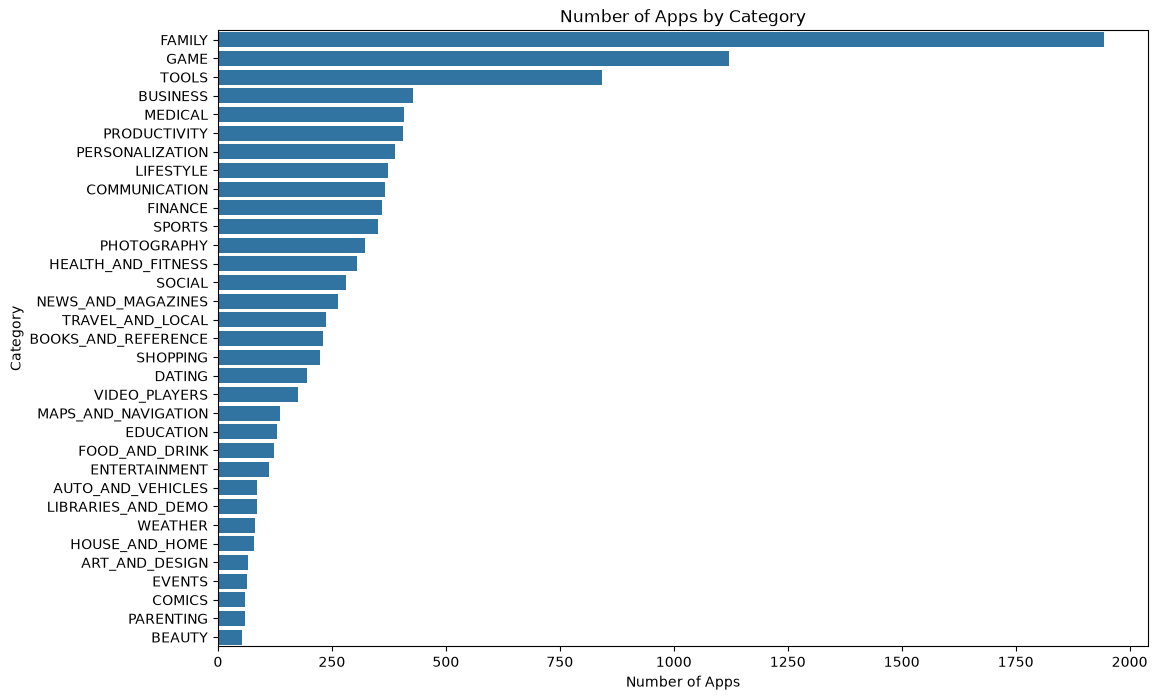

In [41]:
plt.figure(figsize=(12,8))
sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)
plt.title("Number of Apps by Category")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.show()

### Observation - App Distribution Across Categories

The bar chart shows that Family has the highest number of apps, followed by Game and Tools, making these the most saturated categories. Categories such as Business, Medical, Productivity, Personalization, Lifestyle, Communication, and Finance have a moderate number of apps. On the other hand, Beauty, Parenting, Comics, Events, Art and Design have comparatively fewer apps.

Overall, the app distribution is highly uneven, with a fewer categories containing a large share of the apps, indicating greater competition and saturation in those categories.

## 4.Rating Analysis

### Distribution of App Ratings

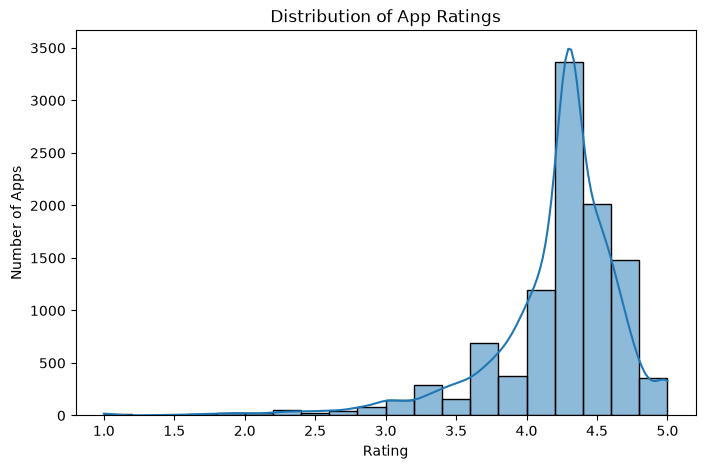

In [42]:
plt.figure(figsize=(8,5))
sns.histplot(
    apps['Rating'],
    bins=20,
    kde=True
)
plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")

plt.show()

### Average rating by Category

In [43]:
category_rating = (
    apps.groupby('Category')['Rating']
    .mean()
    .sort_values(ascending=False)
)

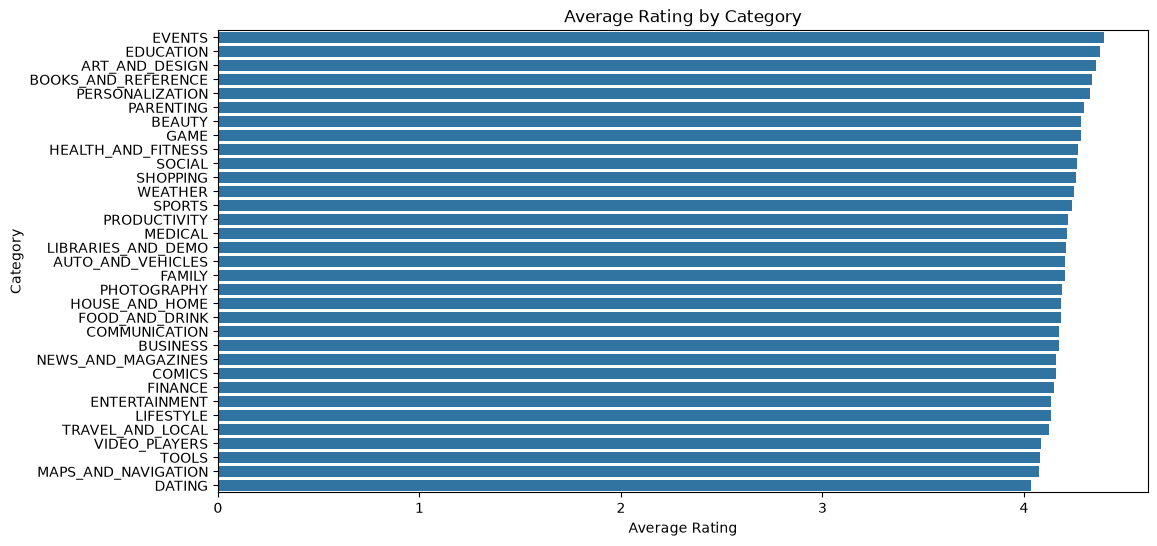

In [44]:
plt.figure(figsize=(12,6))
sns.barplot(
    x=category_rating.values,
    y=category_rating.index
)
plt.title("Average Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.show()

### Observation
Average ratings are relatively similar across categories, with only modest differences between the highest and lowest rated categories.

## 5.Size vs Installs analysis

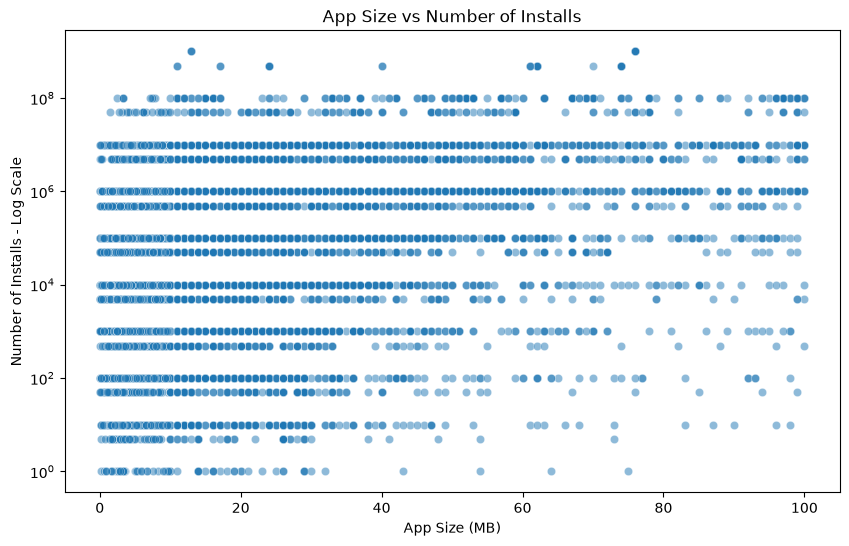

In [45]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=apps,
    x='Size_MB',
    y='Installs',
    alpha=0.5
)

plt.yscale('log')

plt.title("App Size vs Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs - Log Scale")

plt.show()

In [46]:
apps[['Size_MB', 'Installs']].corr()

,Size_MB,Installs
Size_MB,1.000000,0.168872
Installs,0.168872,1.000000


### Observation-App size vs Number of Installs
- The Correlation between App Size and Number of Installs is 0.1689.
- This indicates a weak positive correlation between the two variables.
- As app size increases, the number of installs tends to increase slightly, but the relationship is not strong.
- The scatter plot also shows that apps of different sizes can have widely different numbers of installs.
- Therefore, app size does not have a major influence on the number of installs.

## 6.Pricing Analysis

In [47]:
apps['Type'].value_counts()

Type
Free    9591
Paid     765
Name: count, dtype: int64

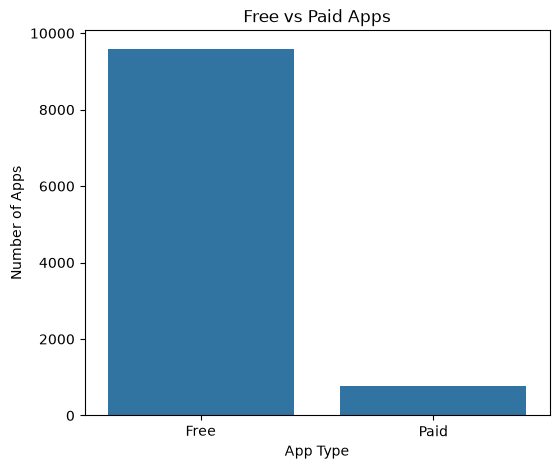

In [48]:
plt.figure(figsize=(6,5))
sns.countplot(
    data=apps,
    x='Type'
)
plt.title("Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.show()

### Observation:
Free apps significantly outnumber paid apps on the Google Play Store, indicating a strong preference for free-to-download applications.

### Price distribution for paid apps

In [49]:
paid_apps = apps[apps['Type'] == 'Paid']

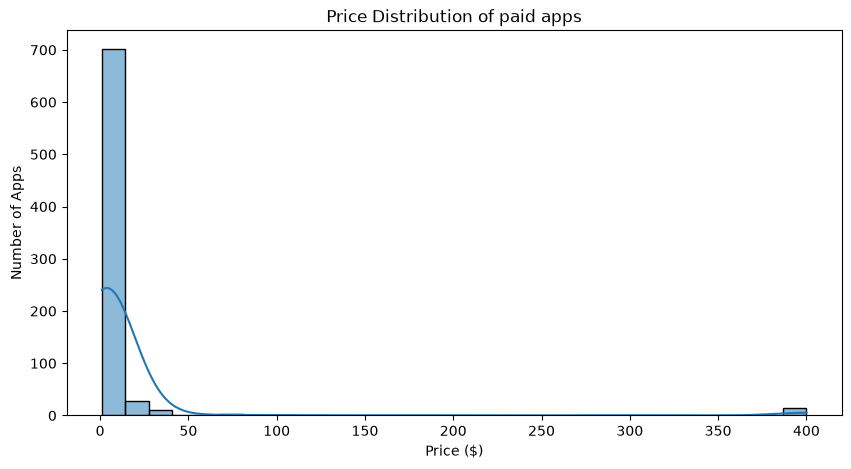

In [50]:
plt.figure(figsize=(10,5))
sns.histplot(
    paid_apps['Price'],
    bins=30,
    kde=True
)
plt.title("Price Distribution of paid apps")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")
plt.show()

### Observation:
The price distribution of paid apps is highly right-skewed, with most apps priced at the lower end and a few unusually expensive apps creating extreme outliers.

### Revenue Estimate by category

In [51]:
paid_apps['Estimated_Revenue']=(
    paid_apps['Price']*paid_apps['Installs']
)

In [52]:
paid_apps[['App', 'Price', 'Installs', 'Estimated_Revenue']].sort_values(
    'Estimated_Revenue',
    ascending=False
).head(10)

,App,Price,Installs,Estimated_Revenue
2241,Minecraft,6.99,10000000.0,69900000.0
4347,Minecraft,6.99,10000000.0,69900000.0
5351,I am rich,399.99,100000.0,39999000.0
5356,I Am Rich Premium,399.99,50000.0,19999500.0
4034,Hitman Sniper,0.99,10000000.0,9900000.0
7417,Grand Theft Auto: San Andreas,6.99,1000000.0,6990000.0
2883,Facetune - For Free,5.99,1000000.0,5990000.0
5578,Sleep as Android Unlock,5.99,1000000.0,5990000.0
8804,DraStic DS Emulator,4.99,1000000.0,4990000.0
4367,I'm Rich - Trump Edition,400.00,10000.0,4000000.0


## 7.Sentiment Analysis on User Reviews

In [53]:
review.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [54]:
review['Translated_Review'].isnull().sum()

np.int64(987)

In [55]:
reviews_clean = review.dropna(
    subset=['Translated_Review']
).copy()

In [56]:
sia = SentimentIntensityAnalyzer()

In [57]:
reviews_clean['compound'] = reviews_clean['Translated_Review'].apply(
    lambda x: sia.polarity_scores(x)['compound']
)

In [58]:
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'
        

In [59]:
reviews_clean['VADER_Sentiment'] = reviews_clean['compound'].apply(
    classify_sentiment
)

In [60]:
reviews_clean['VADER_Sentiment'].value_counts()

VADER_Sentiment
Positive    20129
Negative     5852
Neutral      3711
Name: count, dtype: int64

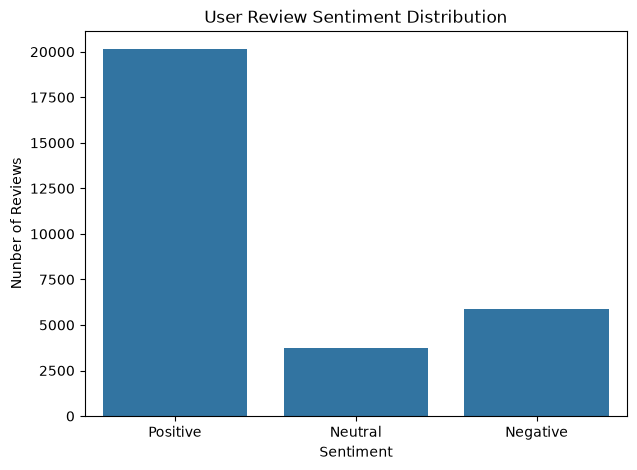

In [61]:
plt.figure(figsize=(7,5))
sns.countplot(
    data=reviews_clean,
    x='VADER_Sentiment'
)
plt.title("User Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Nunber of Reviews")
plt.show()

### Observation:
Positive reviews dominate the user sentiment analysis, indicating that most users express satisfaction with apps. However, the presence of negative and neutral reviews highlights opportunities for developers to improve app quality and user experience.

## 8.Sentiment by App Category

In [64]:
apps_category = apps[['App', 'Category']]

In [65]:
reviews_with_category =  reviews_clean.merge(
    apps_category,
    on='App',
    how='left'
)
reviews_with_category.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity,compound,VADER_Sentiment,Category
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333,0.9531,Positive,HEALTH_AND_FITNESS
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462,0.6597,Positive,HEALTH_AND_FITNESS
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000,0.6249,Positive,HEALTH_AND_FITNESS
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000,0.6369,Positive,HEALTH_AND_FITNESS
4,10 Best Foods for You,Best way,Positive,1.00,0.300000,0.6369,Positive,HEALTH_AND_FITNESS


### Calculate Sentiment by Category

In [66]:
category_sentiment = (
    reviews_with_category
    .groupby(['Category', 'VADER_Sentiment'])
    .size()
    .unstack(fill_value=0)
)

In [67]:
category_sentiment

VADER_Sentiment,Negative,Neutral,Positive
Category,,,
ART_AND_DESIGN,47,43,264
AUTO_AND_VEHICLES,14,37,232
BEAUTY,63,62,192
BOOKS_AND_REFERENCE,131,85,495
BUSINESS,140,158,505
COMICS,2,7,71
COMMUNICATION,303,168,817
DATING,352,223,912
EDUCATION,78,80,579


In [68]:
category_sentiment_percentage = (
    category_sentiment
    .div(category_sentiment.sum(axis=1), axis=0)
    *100
)

### Find categories with most positive sentiment

In [69]:
positive_categories = (
    category_sentiment_percentage['Positive']
    .sort_values(ascending=False)
)
positive_categories.head(10)

Category
COMICS                88.750000
AUTO_AND_VEHICLES     81.978799
EVENTS                79.487179
EDUCATION             78.561737
HEALTH_AND_FITNESS    77.171610
FOOD_AND_DRINK        75.075529
ART_AND_DESIGN        74.576271
FAMILY                73.718310
PARENTING             73.046875
GAME                  72.237168
Name: Positive, dtype: float64

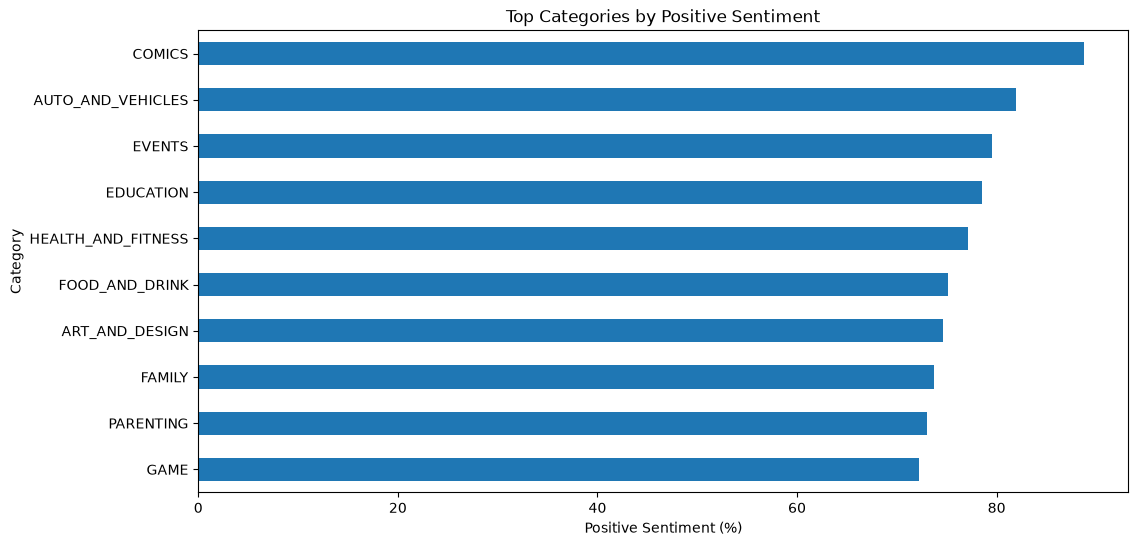

In [70]:
plt.figure(figsize=(12,6))
positive_categories.head(10).sort_values().plot(
    kind='barh'
)
plt.title("Top Categories by Positive Sentiment")
plt.xlabel("Positive Sentiment (%)")
plt.ylabel("Category")
plt.show()

### Observation:
The Comics category shows the highest positive sentiment, followed by categories such as Auto & Vehicles and Events. This suggests that users express more favorable opinions about apps in these categories.

### Find categories with most negative sentiment

In [71]:
negative_categories = (
    category_sentiment_percentage['Negative']
    .sort_values(ascending=False)
)

negative_categories.head(10)

Category
SOCIAL                34.153846
VIDEO_PLAYERS         31.595092
ENTERTAINMENT         26.758939
NEWS_AND_MAGAZINES    24.637681
DATING                23.671822
FINANCE               23.592663
COMMUNICATION         23.524845
SPORTS                23.416149
GAME                  22.802109
TRAVEL_AND_LOCAL      22.549575
Name: Negative, dtype: float64

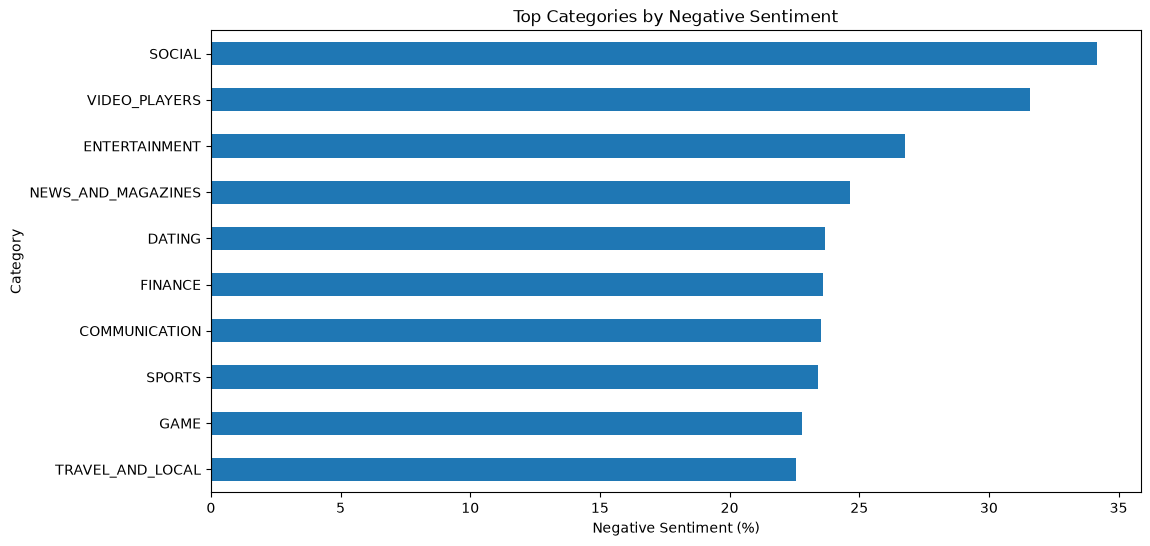

In [72]:
plt.figure(figsize=(12,6))

negative_categories.head(10).sort_values().plot(
    kind='barh'
)

plt.title("Top Categories by Negative Sentiment")
plt.xlabel("Negative Sentiment (%)")
plt.ylabel("Category")

plt.show()

### Observation:
The Social category has the highest negative sentiment, followed by Video Players and Entertainment. This suggests that apps in these categories may face more user dissatisfaction and could benefit from improvements based on user feedback.

## Interactive Plotly Visualization

In [73]:
plotly_data = (
    apps.groupby('Category', as_index=False)['Installs']
    .sum()
    .sort_values('Installs', ascending=False)
)

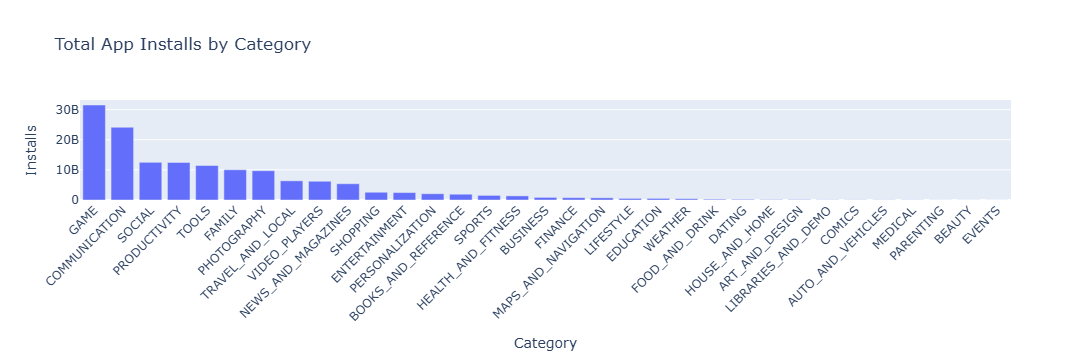

In [74]:
fig = px.bar(
    plotly_data,
    x='Category',
    y='Installs',
    title='Total App Installs by Category',
    hover_data=['Installs']
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

### Observation: 
The Game category has the highest total number of installs, followed by Communication. This indicates strong user demand for gaming and communication apps compared with other categories.

In [75]:
total_apps = apps['App'].nunique()

total_installs = apps['Installs'].sum()

average_rating = apps['Rating'].mean()

paid_percentage = (
    (apps['Type'] == 'Paid').mean() * 100
)

print("Total Apps:", total_apps)
print("Total Installs:", total_installs)
print("Average Rating:", round(average_rating, 2))
print("Paid Apps %:", round(paid_percentage, 2))

Total Apps: 9659
Total Installs: 146631914527.0
Average Rating: 4.2
Paid Apps %: 7.39


## 3 Data driven insights to build a new app
### 1. Games have the highest app installs
- GAME has the highest total installs, at around 30B+.
- COMMUNICATION is second, at around 24B.
- This shows that entertainment and communication apps have a very large user reach.
### 2. Social apps show the highest negative sentiment
- SOCIAL has the highest negative sentiment, around 34%.
- VIDEO_PLAYERS and ENTERTAINMENT follow with roughly 30% and 26%.
- This suggests that these categories may have more user dissatisfaction or complaints in their reviews compared with many other categories.
### 3. High popularity does not always mean better user sentiment
- GAME has the highest installs, but it is not the category with the highest negative sentiment.
- Meanwhile, SOCIAL has lower overall installs than Games but the highest negative sentiment.
- So, number of users/downloads and user satisfaction are different dimensions; a popular category can still have significant negative feedback.

## Overall conclusion
The analysis shows that app popularity is concentrated in Games and Communication, while negative user sentiment is particularly high in Social, Video Players, and Entertainment. Therefore, developers should not focus only on increasing installs—they should also analyze user feedback and address the issues causing negative experiences.